#### Data Loading & Inspection

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set a clean, professional aesthetic for the plots
sns.set_theme(style="whitegrid", context="talk")

# Load the annotated variants
df = pd.read_csv("../annot/somatic_mutations_annotated.csv")

print(f"Total somatic mutations analyzed: {len(df)}")
display(df.head())

Total somatic mutations analyzed: 272


,Location,Allele,Gene,Consequence,Impact
0,chr6:143108,A/1,SEPTIN14P6,non_coding_transcript_exon_variant,MODIFIER
1,chr6:325357,A/1,DUSP22,intron_variant,MODIFIER
2,chr6:325783,C/1,DUSP22,intron_variant,MODIFIER
3,chr6:325901,A/1,DUSP22,intron_variant,MODIFIER
4,chr6:325916,G/1,DUSP22,intron_variant,MODIFIER


#### Figure 1 - Mutation Consequences

C:\Users\Jaydeep\AppData\Local\Temp\ipykernel_7356\525811357.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=consequence_counts.values, y=consequence_counts.index, palette="viridis")


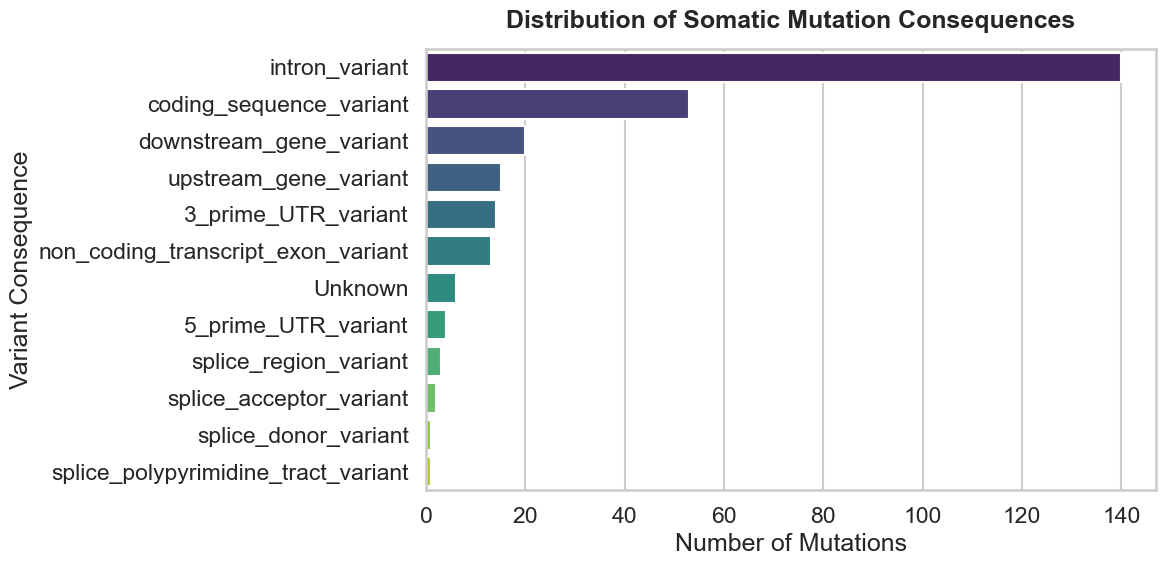

In [2]:
# Create a new figure
plt.figure(figsize=(12, 6))

# Count the frequency of each consequence
consequence_counts = df['Consequence'].value_counts()

# Generate a horizontal bar plot
sns.barplot(x=consequence_counts.values, y=consequence_counts.index, palette="viridis")

# Formatting
plt.title("Distribution of Somatic Mutation Consequences", pad=15, weight='bold')
plt.xlabel("Number of Mutations")
plt.ylabel("Variant Consequence")
plt.tight_layout()
plt.show()

#### Figure 2 - Clinical Impact Severity

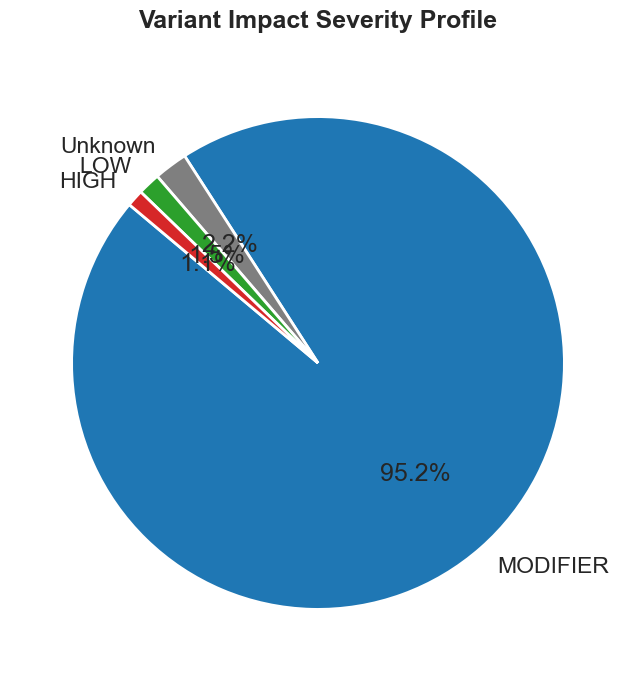

In [3]:
plt.figure(figsize=(8, 8))

# Count the frequency of impact levels
impact_counts = df['Impact'].value_counts()

# Standardized clinical color mapping
impact_colors = {
    "HIGH": "#d62728",      # Red
    "MODERATE": "#ff7f0e",  # Orange
    "LOW": "#2ca02c",       # Green
    "MODIFIER": "#1f77b4"   # Blue
}
colors = [impact_colors.get(i, "#7f7f7f") for i in impact_counts.index]

# Generate pie chart with white borders for clean separation
plt.pie(impact_counts, labels=impact_counts.index, autopct='%1.1f%%', 
        colors=colors, startangle=140, wedgeprops={'edgecolor': 'white', 'linewidth': 2})

plt.title("Variant Impact Severity Profile", weight='bold', pad=20)
plt.show()

#### Figure 3 - Top Mutated Genes

C:\Users\Jaydeep\AppData\Local\Temp\ipykernel_7356\1192993143.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_genes.values, y=top_genes.index, palette="mako")


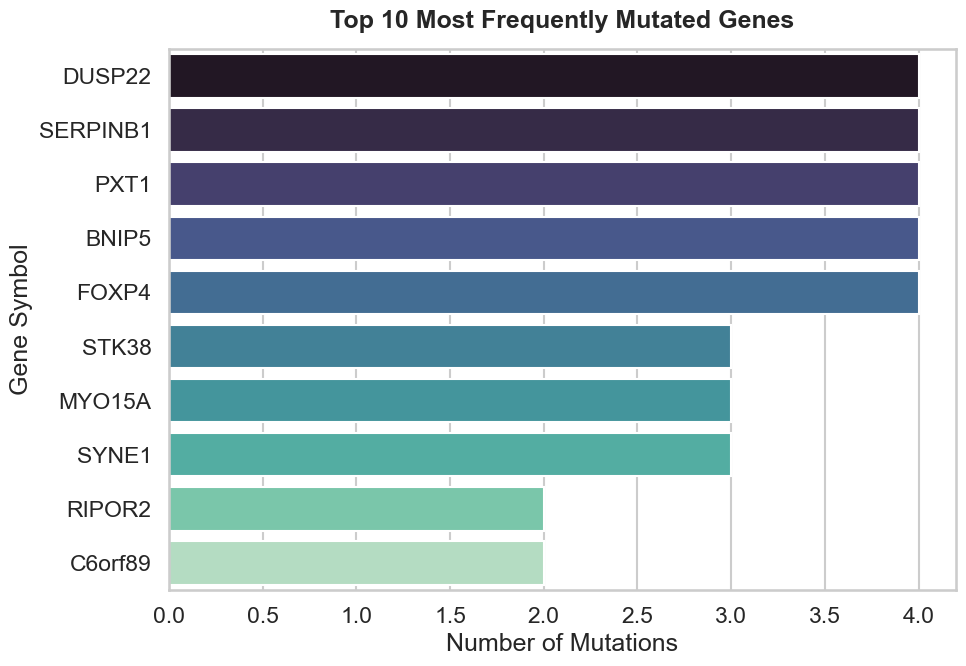

In [4]:
plt.figure(figsize=(10, 7))

# Filter out unannotated regions (intergenic) to focus strictly on known genes
genes_df = df[~df['Gene'].isin(['Unknown', '-', ''])]
top_genes = genes_df['Gene'].value_counts().head(10)

# Generate a bar plot using a distinct color palette
sns.barplot(x=top_genes.values, y=top_genes.index, palette="mako")

# Formatting
plt.title("Top 10 Most Frequently Mutated Genes", pad=15, weight='bold')
plt.xlabel("Number of Mutations")
plt.ylabel("Gene Symbol")
plt.tight_layout()
plt.show()